In [236]:
import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.nn.functional as F
from torchvision.datasets import CIFAR100
from torchvision.datasets import CIFAR10
import torchvision.transforms as tt
from torchvision.utils import make_grid
from torch.utils.data.dataloader import DataLoader
from torch.utils.data import random_split,ConcatDataset

%matplotlib inline

In [237]:
project_name = "cifar100"
import os
os.environ["CUDA_VISIBLE_DEVICES"] = str(0)

In [238]:
stats = ((0.5074,0.4867,0.4411),(0.2011,0.1987,0.2025))
train_transform = tt.Compose([
    tt.RandomHorizontalFlip(),
    tt.RandomCrop(32,padding=4,padding_mode="reflect"),
    tt.ToTensor(),
    tt.Normalize(*stats)
])

test_transform = tt.Compose([
    tt.ToTensor(),
    tt.Normalize(*stats)
])

In [239]:
train_data = CIFAR100(download=True,root="./data",transform=train_transform)
test_data = CIFAR100(root="./data",train=False,transform=test_transform)

Files already downloaded and verified


In [240]:
for image,label in train_data:
    print("Image shape: ",image.shape)
    print("Image tensor: ", image)
    print("Label: ", label)
    break

Image shape:  torch.Size([3, 32, 32])
Image tensor:  tensor([[[ 2.4495,  2.4495,  2.4495,  ...,  1.9815,  1.8450,  1.6110],
         [ 2.4495,  2.4495,  2.4495,  ...,  1.6500,  0.9870,  0.5385],
         [ 2.4495,  2.4495,  2.4495,  ...,  1.2405,  0.0705, -0.0660],
         ...,
         [-0.7096, -0.5926, -0.0660,  ..., -0.3001, -0.2806, -0.7486],
         [ 0.2070,  0.0900,  0.2070,  ...,  0.0315, -0.1050, -0.3976],
         [ 0.5385,  0.6165,  0.5580,  ...,  0.1290, -0.0075, -0.2026]],

        [[ 2.5833,  2.5833,  2.5833,  ...,  2.2083,  1.9715,  1.8136],
         [ 2.5833,  2.5833,  2.5833,  ...,  1.7741,  0.7281,  0.2150],
         [ 2.5833,  2.5833,  2.5833,  ...,  0.9847, -0.6534, -0.9692],
         ...,
         [ 0.0965,  0.2150,  0.7084,  ..., -0.2390,  0.1952, -0.6534],
         [ 1.0044,  0.9649,  1.0833,  ...,  0.0768,  0.0176, -0.4166],
         [ 1.3004,  1.4978,  1.4781,  ...,  0.1163, -0.0613, -0.3179]],

        [[ 2.7600,  2.7600,  2.7600,  ...,  2.4501,  1.9854,  1

In [241]:
train_data.classes

['apple',
 'aquarium_fish',
 'baby',
 'bear',
 'beaver',
 'bed',
 'bee',
 'beetle',
 'bicycle',
 'bottle',
 'bowl',
 'boy',
 'bridge',
 'bus',
 'butterfly',
 'camel',
 'can',
 'castle',
 'caterpillar',
 'cattle',
 'chair',
 'chimpanzee',
 'clock',
 'cloud',
 'cockroach',
 'couch',
 'crab',
 'crocodile',
 'cup',
 'dinosaur',
 'dolphin',
 'elephant',
 'flatfish',
 'forest',
 'fox',
 'girl',
 'hamster',
 'house',
 'kangaroo',
 'keyboard',
 'lamp',
 'lawn_mower',
 'leopard',
 'lion',
 'lizard',
 'lobster',
 'man',
 'maple_tree',
 'motorcycle',
 'mountain',
 'mouse',
 'mushroom',
 'oak_tree',
 'orange',
 'orchid',
 'otter',
 'palm_tree',
 'pear',
 'pickup_truck',
 'pine_tree',
 'plain',
 'plate',
 'poppy',
 'porcupine',
 'possum',
 'rabbit',
 'raccoon',
 'ray',
 'road',
 'rocket',
 'rose',
 'sea',
 'seal',
 'shark',
 'shrew',
 'skunk',
 'skyscraper',
 'snail',
 'snake',
 'spider',
 'squirrel',
 'streetcar',
 'sunflower',
 'sweet_pepper',
 'table',
 'tank',
 'telephone',
 'television',
 'tig

In [242]:
# train_classes_items = dict()

# for train_item in train_data:
#     label = train_data.classes[train_item[1]]
#     if label not in train_classes_items:
#         train_classes_items[label] = 1
#     else:
#         train_classes_items[label] += 1

# train_classes_items
        

In [243]:
# test_classes_items = dict()
# for test_item in test_data:
#     label = test_data.classes[test_item[1]]
#     if label not in test_classes_items:
#         test_classes_items[label] = 1
#     else:
#         test_classes_items[label] += 1

# test_classes_items

In [244]:
BATCH_SIZE=128
train_dl = DataLoader(train_data,BATCH_SIZE,num_workers=4,pin_memory=True,shuffle=True)
test_dl = DataLoader(test_data,BATCH_SIZE,num_workers=4,pin_memory=True)

In [245]:
def show_batch(dl):
    for batch in dl:
        images,labels = batch
        fig, ax = plt.subplots(figsize=(7.5,7.5))
        ax.set_yticks([])
        ax.set_xticks([])
        ax.imshow(make_grid(images[:20],nrow=5).permute(1,2,0))
        break

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


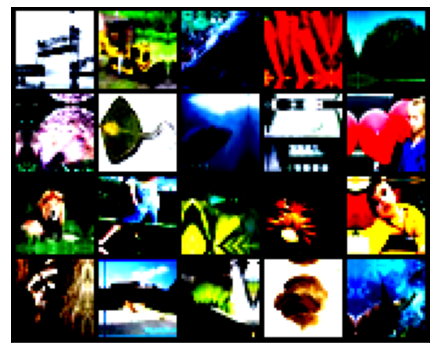

In [246]:
show_batch(train_dl)

In [247]:
def get_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    return torch.device("cpu")

def to_device(data,device):
    if isinstance(data,(list,tuple)):
        return [to_device(x,device) for x in data]
    return data.to(device,non_blocking=True)


class ToDeviceLoader:
    def __init__(self,data,device):
        self.data = data
        self.device = device
        
    def __iter__(self):
        for batch in self.data:
            yield to_device(batch,self.device)
            
    def __len__(self):
        return len(self.data)


In [248]:
device = get_device()
print(device)

train_dl = ToDeviceLoader(train_dl,device)
test_dl = ToDeviceLoader(test_dl,device)

cuda


In [249]:
def accuracy(predicted,actual):
    _, predictions = torch.max(predicted,dim=1)
    return torch.tensor(torch.sum(predictions==actual).item()/len(predictions))

class BaseModel(nn.Module):
    def training_step(self,batch):
        images,labels = batch
        out = self(images)
        loss = F.cross_entropy(out,labels)
        return loss
    
    def validation_step(self,batch):
        images,labels = batch
        out = self(images)
        loss = F.cross_entropy(out,labels)
        acc = accuracy(out,labels)
        return {"val_loss":loss.detach(),"val_acc":acc}
    
    def validation_epoch_end(self,outputs):
        batch_losses = [loss["val_loss"] for loss in outputs]
        loss = torch.stack(batch_losses).mean()
        batch_accuracy = [accuracy["val_acc"] for accuracy in outputs]
        acc = torch.stack(batch_accuracy).mean()
        return {"val_loss":loss.item(),"val_acc":acc.item()}
    
    def epoch_end(self, epoch, result):
        print("Epoch [{}], last_lr: {:.5f}, train_loss: {:.4f}, val_loss: {:.4f}, val_acc: {:.4f}".format(
            epoch, result['lrs'][-1], result['train_loss'], result['val_loss'], result['val_acc']))
        
        

In [250]:
def conv_shortcut(in_channel,out_channel,stride):
    layers = [nn.Conv2d(in_channel,out_channel,kernel_size=(1,1),stride=(stride,stride)),
             nn.BatchNorm2d(out_channel)]
    return nn.Sequential(*layers)

def block(in_channel,out_channel,k_size,stride, conv=False):
    layers = None
    
    first_layers = [nn.Conv2d(in_channel,out_channel[0],kernel_size=(1,1),stride=(1,1)),
                    nn.BatchNorm2d(out_channel[0]),
                    nn.ReLU(inplace=True)]
    if conv:
        first_layers[0].stride=(stride,stride)
    
    second_layers = [nn.Conv2d(out_channel[0],out_channel[1],kernel_size=(k_size,k_size),stride=(1,1),padding=1),
                    nn.BatchNorm2d(out_channel[1])]

    layers = first_layers + second_layers
    
    return nn.Sequential(*layers)
    

class Resnet50(BaseModel):
    
    def __init__(self,in_channels,num_classes):
        super().__init__()
        
        self.stg1 = nn.Sequential(
                                   nn.Conv2d(in_channels=in_channels,out_channels=64,kernel_size=(3),stride=(1),padding=1),
                                   nn.BatchNorm2d(64),
                                   nn.ReLU(inplace=True),
                                   nn.MaxPool2d(kernel_size=3,stride=2))
        
        ##stage 2
        self.convShortcut2 = conv_shortcut(64,256,1)
        
        self.conv2 = block(64,[64,256],3,1,conv=True)
        self.ident2 = block(256,[64,256],3,1)

        
        ##stage 3
        self.convShortcut3 = conv_shortcut(256,512,2)
        
        self.conv3 = block(256,[128,512],3,2,conv=True)
        self.ident3 = block(512,[128,512],3,2)

        
        ##stage 4
        self.convShortcut4 = conv_shortcut(512,1024,2)
        
        self.conv4 = block(512,[256,1024],3,2,conv=True)
        self.ident4 = block(1024,[256,1024],3,2)
        
        
        ##Classify
        self.classifier = nn.Sequential(
                                       nn.AvgPool2d(kernel_size=(4)),
                                       nn.Flatten(),
                                       nn.Linear(1024,num_classes))
        
    def forward(self,inputs):
        out = self.stg1(inputs)
        
        #stage 2
        out = F.relu(self.conv2(out) + self.convShortcut2(out))
        out = F.relu(self.ident2(out) + out)
        out = F.relu(self.ident2(out) + out)
        
        # out = F.relu(self.ident2(out) + out)
        
        #stage3
        out = F.relu(self.conv3(out) + (self.convShortcut3(out)))
        out = F.relu(self.ident3(out) + out)
        out = F.relu(self.ident3(out) + out)
        out = F.relu(self.ident3(out) + out)
        
        # out = F.relu(self.ident3(out) + out)
        
#         stage4             
        out = F.relu(self.conv4(out) + (self.convShortcut4(out)))
        out = F.relu(self.ident4(out) + out)
        out = F.relu(self.ident4(out) + out)
        out = F.relu(self.ident4(out) + out)
        out = F.relu(self.ident4(out) + out)
        # out = F.relu(self.ident4(out) + out)
        
        # out = F.relu(self.ident4(out) + out)
        
        out = self.classifier(out)#100x1024
        
        return out
        
        
        

In [251]:
model = Resnet50(3,100)


In [252]:
model = to_device(model,device)

In [253]:
for images, labels in train_dl:
    print(images.shape)
    result = model(images)
    print(result.shape)
    print(result)
    break

torch.Size([128, 3, 32, 32])
torch.Size([128, 100])
tensor([[-0.5979, -1.5058,  0.2282,  ...,  0.9194,  0.4446, -0.0401],
        [-1.0394, -1.1592, -0.0476,  ...,  0.8813,  0.0334,  0.7238],
        [-1.1995, -0.8302,  0.5544,  ...,  0.9134,  0.3900, -0.1787],
        ...,
        [-0.8668, -0.7110, -0.5297,  ...,  0.6388, -0.0436,  0.4068],
        [-0.6848, -0.7764, -0.0375,  ...,  0.5612,  0.1195,  0.2756],
        [-0.6239, -1.2327, -0.1455,  ...,  0.5026,  0.2455,  0.5150]],
       device='cuda:0', grad_fn=<AddmmBackward>)


In [254]:
@torch.no_grad()
def evaluate(model,test_dl):
    model.eval()
    outputs = [model.validation_step(batch) for batch in test_dl]
    return model.validation_epoch_end(outputs)

def get_lr(optimizer):
    for param_group in optimizer.param_groups:
        return param_group['lr']

def fit (epochs,train_dl,test_dl,model,optimizer,max_lr,weight_decay,scheduler,grad_clip=None):
    torch.cuda.empty_cache()
    
    history = []
    
    optimizer = optimizer(model.parameters(),max_lr,weight_decay=weight_decay)
    
    scheduler = scheduler(optimizer,max_lr,epochs=epochs,steps_per_epoch=len(train_dl))
    
    for epoch in range(epochs):
        model.train()
        
        train_loss = []
        
        lrs = []
        
        for batch in train_dl:
            loss = model.training_step(batch)
            
            train_loss.append(loss)
            
            loss.backward()
            
            if grad_clip:
                nn.utils.clip_grad_value_(model.parameters(),grad_clip)
            
            optimizer.step()
            optimizer.zero_grad()
            
            scheduler.step()
            lrs.append(get_lr(optimizer))
        result = evaluate(model,test_dl)
        result["train_loss"] = torch.stack(train_loss).mean().item()
        result["lrs"] = lrs
        
        model.epoch_end(epoch,result)
        history.append(result)
        
    return history
            

In [255]:
history = [evaluate(model,test_dl)]

In [256]:
print(history)

[{'val_loss': 4.613028526306152, 'val_acc': 0.01186708826571703}]


In [257]:
epochs = 25
optimizer = torch.optim.Adam
max_lr=0.001
grad_clip = 0.1
weight_decay = 1e-4
scheduler = torch.optim.lr_scheduler.OneCycleLR

In [258]:
%%time
history += fit(epochs=epochs,train_dl=train_dl,test_dl=test_dl,model=model,optimizer=optimizer,max_lr=max_lr,grad_clip=grad_clip,
              weight_decay=weight_decay,scheduler=torch.optim.lr_scheduler.OneCycleLR)

Epoch [0], last_lr: 0.00008, train_loss: 3.7431, val_loss: 3.3538, val_acc: 0.1952
Epoch [1], last_lr: 0.00020, train_loss: 3.0755, val_loss: 2.9791, val_acc: 0.2636
Epoch [2], last_lr: 0.00037, train_loss: 2.7425, val_loss: 2.6355, val_acc: 0.3278
Epoch [3], last_lr: 0.00057, train_loss: 2.4948, val_loss: 2.5907, val_acc: 0.3418
Epoch [4], last_lr: 0.00076, train_loss: 2.3133, val_loss: 2.3068, val_acc: 0.3931
Epoch [5], last_lr: 0.00091, train_loss: 2.1349, val_loss: 2.3501, val_acc: 0.3845
Epoch [6], last_lr: 0.00099, train_loss: 1.9763, val_loss: 2.0673, val_acc: 0.4443
Epoch [7], last_lr: 0.00100, train_loss: 1.7966, val_loss: 1.8728, val_acc: 0.4894
Epoch [8], last_lr: 0.00098, train_loss: 1.6438, val_loss: 1.9197, val_acc: 0.4810
Epoch [9], last_lr: 0.00095, train_loss: 1.5319, val_loss: 1.7501, val_acc: 0.5118
Epoch [10], last_lr: 0.00090, train_loss: 1.4318, val_loss: 1.6352, val_acc: 0.5465
Epoch [11], last_lr: 0.00085, train_loss: 1.3349, val_loss: 1.5984, val_acc: 0.5537
Ep

In [259]:
def plot_acc(history):
    plt.plot([x["val_acc"] for x in history],"-x")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")

def plot_loss(history):
    plt.plot([x.get("train_loss") for x in history], "-bx")
    plt.plot([x["val_loss"] for x in history],"-rx")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend(["train loss","val loss"])
    
def plot_lrs(history):
    plt.plot(np.concatenate([x.get("lrs",[]) for x in history]))
    plt.xlabel("Batch number")
    plt.ylabel("Learning rate")

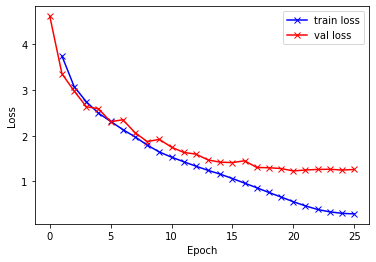

In [260]:
plot_loss(history)

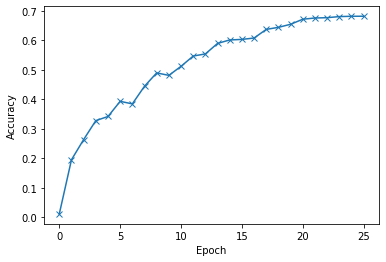

In [261]:
plot_acc(history)

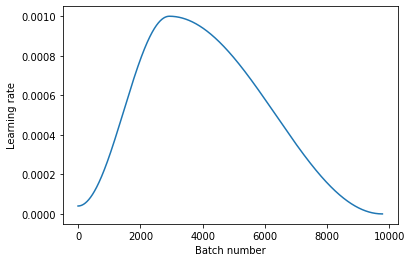

In [262]:
plot_lrs(history)

In [263]:
torch.save(model.state_dict(), 'cifar100-resnet.pth')
jovian.log_hyperparams(arch='Resnet', 
                       epochs=epochs, 
                       lr=max_lr, 
                       scheduler='one-cycle', 
                       weight_decay=weight_decay, 
                       grad_clip=grad_clip,
                       opt=optimizer.__name__)
jovian.log_metrics(val_loss=history[-1]['val_loss'], 
                   val_acc=history[-1]['val_acc'],
                   train_loss=history[-1]['train_loss'])
jovian.commit(project=project_name,outputs=['cifar100-resnet.pth'])

NameError: name 'jovian' is not defined